# Data Science — Zajęcia 2

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/data_science/zajecia_2.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science/zajecia_2/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Statystyka opisowa bez wzorów — co naprawdę mówią liczby

Co miesiąc w wiadomościach pada kwota „przeciętnego wynagrodzenia w Polsce"
i co miesiąc spora część słuchaczy myśli: chyba nie u mnie. I ma rację — bo
**przeciętne** w tym zdaniu znaczy **średnie**, a średnia w przypadku zarobków
zachowuje się w bardzo specyficzny sposób.

Dziś uczymy się czytać liczby, które opisują dane: średnią, medianę,
rozproszenie, wartości odstające i korelację. Bez wyprowadzania wzorów — za to
z pytaniem, które zadaje sobie każdy dobry analityk: **co ta liczba mówi, a co
ukrywa?** Najpierw w Excelu, potem — jak na poprzednich zajęciach — to samo
w Pythonie.

Po dzisiejszych zajęciach będziesz w stanie:

- wyjaśnić, kiedy średnia kłamie i dlaczego GUS publikuje także medianę,
- opisać rozproszenie danych kwartylami i odchyleniem standardowym — i wiedzieć,
  dlaczego w finansach to po prostu **ryzyko**,
- znaleźć wartości odstające i zdecydować, co z nimi zrobić,
- policzyć korelację, odczytać ją z wykresu punktowego i nie wyciągnąć z niej
  wniosku, którego ona nie dowodzi,
- dobrać wykres do pytania i rozpoznać wykres, który manipuluje.



## Część 2: to samo w Pythonie

Jak na poprzednich zajęciach: te same pytania, te same odpowiedzi, tylko
zapisane jako kod — a do tego kilka rzeczy, które w Pythonie są dużo prostsze
niż w Excelu.

### Wczytanie i `describe()` — teraz już rozumiesz wszystko

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science/dane/gospodarstwa_2026.csv"
df = pd.read_csv(URL)

df.describe().round(2)

,liczba_osob,dochod,wydatki,wydatki_zywnosc
count,400.00,400.00,400.00,400.00
mean,2.68,7066.20,5804.80,1244.62
std,1.40,5925.91,4513.82,562.23
min,1.00,1210.00,1030.00,310.00
25%,1.00,4032.50,3450.00,787.50
50%,2.00,5625.00,4775.00,1175.00
75%,4.00,8222.50,6847.50,1600.00
max,6.00,68000.00,51470.00,4280.00


Na zajęciach 1 kazałem patrzeć tylko na `mean`, `min` i `max`. Teraz rozumiesz
każdy wiersz:

- `mean` — średnia, `50%` — **mediana**. Dla dochodu 7 066 kontra 5 625: od
  razu widać, że są skrajnie wysokie wartości.
- `std` — odchylenie standardowe (to samo co `ODCH.STANDARD.PRÓBKI`).
- `25%` i `75%` — pierwszy i trzeci kwartyl.

Jedna komenda daje wszystko, co w Excelu wymagało sześciu formuł na kolumnę.

Pojedyncze miary:

In [2]:
print(df["dochod"].mean(), df["dochod"].median())
print(df["dochod"].quantile([0.25, 0.75]))

7066.2 5625.0
0.25    4032.5
0.75    8222.5
Name: dochod, dtype: float64


### Fundusze — rozproszenie w trzech linijkach

In [3]:
fundusze = pd.DataFrame({
    "fundusz_A": [0.6, 0.4, 0.5, 0.7, 0.3, 0.5, 0.6, 0.4, 0.5, 0.6, 0.4, 0.5],
    "fundusz_B": [3.1, -2.4, 1.8, -1.5, 4.2, -3.0, 2.5, -0.8, 1.2, -2.9, 3.6, 0.2],
})

fundusze.agg(["mean", "std", "min", "max"]).round(2)

,fundusz_A,fundusz_B
mean,0.50,0.5
std,0.11,2.6
min,0.30,-3.0
max,0.70,4.2


`agg` liczy kilka statystyk naraz — znasz go z `groupby` na zajęciach 1.

### Statystyki w grupach

To, co w Excelu wymaga tabeli przestawnej (i w ogóle nie umie mediany), w pandas
to jedna linijka:

In [4]:
df.groupby("klasa_miejscowosci")["dochod"].agg(["mean", "median", "std", "count"]).round(0)

,mean,median,std,count
klasa_miejscowosci,,,,
miasto do 100 tys.,6538.0,5955.0,3723.0,104
miasto powyżej 100 tys.,9287.0,6925.0,8611.0,136
wieś,5522.0,4990.0,3063.0,160


Zobacz duże miasta: średnia **9 287**, mediana **6 925**. Różnica 2 400 zł —
dużo większa niż w pozostałych grupach. Wszystkie bardzo zamożne gospodarstwa
mieszkają w dużych miastach i to one ciągną średnią. Gdyby porównywać tylko
średnie, różnica między miastem a wsią wyglądałaby na dwa razy większą, niż
jest naprawdę dla typowego gospodarstwa.

### Histogram — kształt rozkładu

W Excelu histogram to kilka kliknięć i walka z przedziałami. Tu:

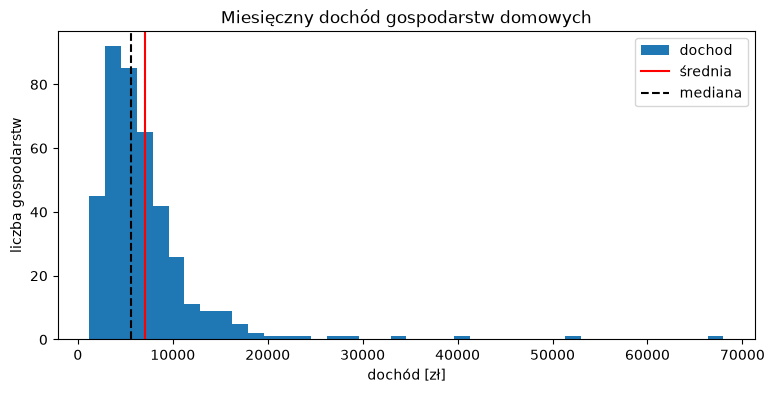

In [5]:
df["dochod"].plot.hist(bins=40, figsize=(9, 4), title="Miesięczny dochód gospodarstw domowych")
plt.axvline(df["dochod"].mean(), color="red", label="średnia")
plt.axvline(df["dochod"].median(), color="black", linestyle="--", label="mediana")
plt.xlabel("dochód [zł]")
plt.ylabel("liczba gospodarstw")
plt.legend()

Histogram dzieli dochody na przedziały (`bins=40` — czterdzieści słupków)
i pokazuje, ile gospodarstw wpada do każdego. Widać to, co dotąd było tylko
liczbami:

- większość gospodarstw jest stłoczona po lewej, między 2 a 10 tys. zł,
- w prawo ciągnie się **długi ogon** — pojedyncze gospodarstwa aż do 68 tys.,
- ogon odciąga **średnią** (czerwona) w prawo od **mediany** (przerywana).

Taki rozkład nazywa się **prawoskośnym**. Mają go prawie wszystkie dane
o pieniądzach: dochody, majątek, ceny, wartość zamówień.

`plt` to biblioteka matplotlib, na której pandas rysuje wykresy. Przez nią
dorysowujemy linie (`axvline` — pionowa linia), podpisy osi i legendę.

### Wykres pudełkowy — kwartyle w obrazku

Text(0, 0.5, 'dochód [zł]')

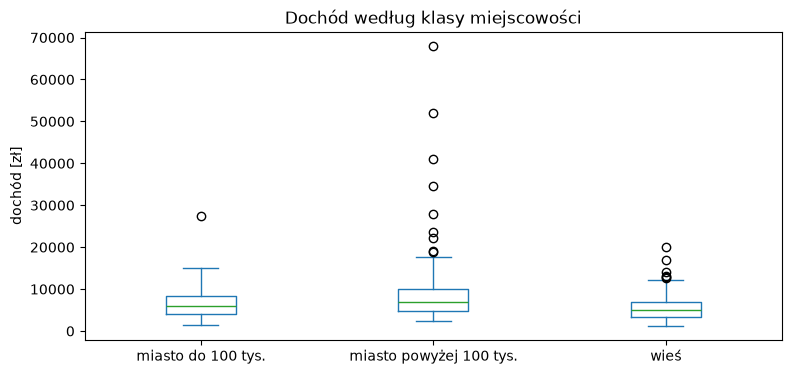

In [6]:
df.plot.box(column="dochod", by="klasa_miejscowosci", figsize=(9, 4))
plt.title("Dochód według klasy miejscowości")
plt.ylabel("dochód [zł]")

Wykres pudełkowy to kwartyle narysowane:

- **pudełko** — od Q1 do Q3, czyli środkowe 50% gospodarstw,
- **kreska w pudełku** — mediana,
- **wąsy** — sięgają do najdalszych wartości, które jeszcze **nie** są
  odstające (półtora IQR od pudełka),
- **kółka** — wartości odstające, każde to jedno gospodarstwo.

Od razu widać, że w dużych miastach pudełko jest najwyżej (typowo zarabia się
więcej) i że tam są wszystkie najbardziej skrajne kółka.

### Wartości odstające

Granica z Excela, policzona w Pythonie:

In [7]:
q1 = df["dochod"].quantile(0.25)
q3 = df["dochod"].quantile(0.75)
granica = q3 + 1.5 * (q3 - q1)

odstajace = df[df["dochod"] > granica]
print(granica, len(odstajace))

14507.5 26


Ile zmienia się wynik bez nich?

In [8]:
typowe = df[df["dochod"] <= granica]

print("wszystkie:", round(df["dochod"].mean()), df["dochod"].median())
print("bez odstających:", round(typowe["dochod"].mean()), typowe["dochod"].median())

wszystkie: 7066 5625.0
bez odstających: 5977 5425.0


Średnia spadła o prawie 1 100 zł, mediana o 200. Jeszcze raz ta sama lekcja:
mediana jest odporna na skrajności, średnia nie.

### Korelacja

Dodajemy udział żywności i liczymy korelacje **wszystkich par kolumn naraz**:

In [9]:
df["udzial_zywnosci"] = df["wydatki_zywnosc"] / df["wydatki"]

df.corr(numeric_only=True).round(2)

,liczba_osob,dochod,wydatki,wydatki_zywnosc,udzial_zywnosci
liczba_osob,1.00,0.41,0.41,0.83,0.20
dochod,0.41,1.00,0.99,0.81,-0.43
wydatki,0.41,0.99,1.00,0.81,-0.45
wydatki_zywnosc,0.83,0.81,0.81,1.00,-0.07
udzial_zywnosci,0.20,-0.43,-0.45,-0.07,1.00


To **macierz korelacji** — w każdej komórce korelacja kolumny z wiersza
z kolumną z nagłówka. Na przekątnej same jedynki (każda kolumna jest idealnie
skorelowana sama ze sobą), a tabela jest symetryczna. `numeric_only=True` pomija
kolumny tekstowe. W Excelu na tę tabelę potrzebowałbyś dziesięciu formuł
`WSP.KORELACJI`.

Wykres punktowy:

<Axes: title={'center': 'Dochód a wydatki gospodarstw domowych'}, xlabel='dochod', ylabel='wydatki'>

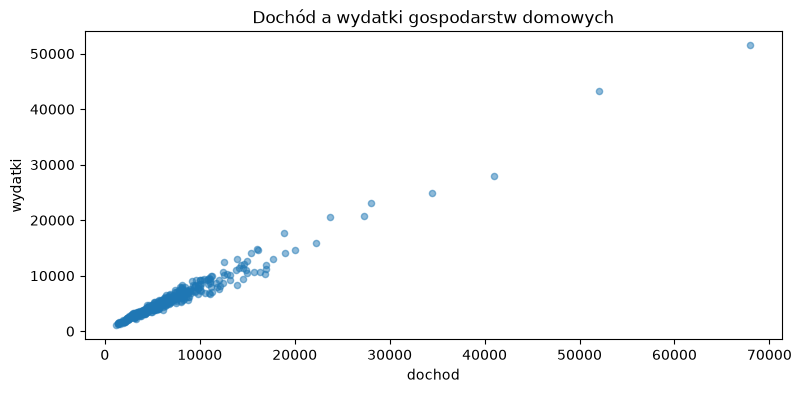

In [10]:
df.plot.scatter(x="dochod", y="wydatki", alpha=0.5, figsize=(9, 4),
                title="Dochód a wydatki gospodarstw domowych")

`alpha=0.5` robi kropki półprzezroczystymi — tam, gdzie się nakładają, robi się
ciemniej i widać, gdzie jest gęsto.

I prawo Engla — tym razem bez odstających gospodarstw, bo przez nie cała chmura
ścisnęłaby się przy lewej krawędzi:

<Axes: title={'center': 'Im wyższy dochód, tym mniejszy udział żywności w wydatkach'}, xlabel='dochod', ylabel='udzial_zywnosci'>

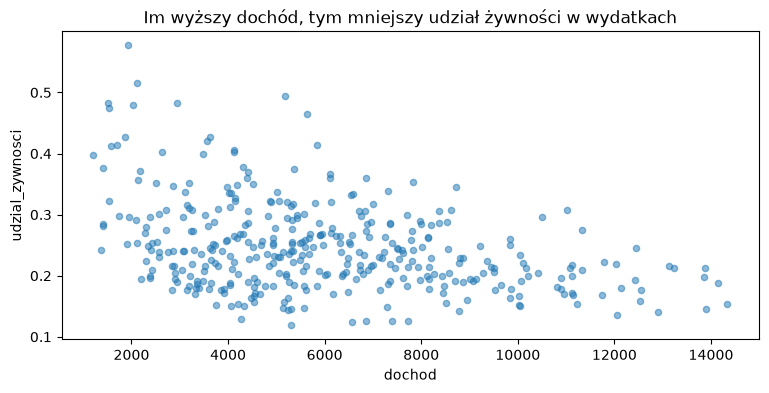

In [11]:
typowe = df[df["dochod"] <= granica]
typowe.plot.scatter(x="dochod", y="udzial_zywnosci", alpha=0.5, figsize=(9, 4),
                    title="Im wyższy dochód, tym mniejszy udział żywności w wydatkach")

Chmura opada w prawo, ale jest szeroka — stąd korelacja −0,43, a nie −0,9.
Związek jest wyraźny, ale daleki od reguły: przy tym samym dochodzie jedne
gospodarstwa wydają na jedzenie 15%, inne 35%.


## Wykresy, które coś pokazują

Na zajęciach 1 była zasada: zanim narysujesz wykres, odpowiedz, **jakie zdanie
ma z niego wynikać**. Dziś ją uzupełniamy — typ wykresu wynika z typu pytania:

| Pytanie | Wykres | Przykład z dziś |
|---|---|---|
| jak rozkładają się wartości? | **histogram** | dochody gospodarstw |
| czym różnią się grupy? | **pudełkowy** albo **słupkowy** | dochód: wieś kontra miasta |
| czy dwie rzeczy idą w parze? | **punktowy** | dochód a wydatki |
| jak coś zmienia się w czasie? | **liniowy** | przychód Południa z zajęć 1 |
| jaki jest udział części w całości? | **słupkowy** (koło — tylko przy 2–3 częściach) | struktura wydatków |

### Jak kłamać wykresem

Dwa banki, oprocentowanie kredytu: 7,1% i 7,4%. Ten sam fakt, dwa wykresy:

![Ten sam wykres słupkowy z osią od 7 procent i od zera](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science/obrazki/zajecia_2_os_od_zera.png)

Po lewej Bank B wygląda na **trzy razy** droższy — bo oś pionowa zaczyna się
od 7%, a nie od zera. Po prawej widać prawdę: różnica jest niewielka. Lewy
wykres nie zawiera żadnej fałszywej liczby, a mimo to wprowadza w błąd.

> ⚠️ **Na co uważać — u siebie i u innych**
>
> - **Wykres słupkowy zawsze od zera.** Długość słupka to wartość — ucięta oś
>   przekłamuje proporcje. (Wykres liniowy może zaczynać się wyżej, bo tam
>   patrzymy na zmianę, a nie na długość.)
> - **Bez 3D.** Trójwymiarowe słupki i koła zniekształcają proporcje i niczego
>   nie dodają.
> - **Odsetki, gdy grupy są różnej wielkości.** 160 gospodarstw wiejskich
>   i 104 małomiasteczkowe — porównuj medianę albo procent, nie sumę.
> - **Podpisane osie z jednostką.** „dochód [zł]" zamiast „dochod".
> - **Tytuł, który mówi wniosek.** „Im wyższy dochód, tym mniejszy udział
>   żywności" zamiast „Wykres 3".


## Ściągawka

| Chcę… | Excel | Python (pandas) |
|---|---|---|
| średnia | `=ŚREDNIA(D2:D401)` | `df["dochod"].mean()` |
| mediana | `=MEDIANA(D2:D401)` | `df["dochod"].median()` |
| średnia z warunkiem | `=ŚREDNIA.JEŻELI(B2:B401;"wieś";D2:D401)` | `df[df["klasa_miejscowosci"] == "wieś"]["dochod"].mean()` |
| mediana z warunkiem | `=MEDIANA(JEŻELI(B2:B401="wieś";D2:D401))` | `df[df["klasa_miejscowosci"] == "wieś"]["dochod"].median()` |
| kwartyl | `=KWARTYL(D2:D401;1)` | `df["dochod"].quantile(0.25)` |
| odchylenie standardowe | `=ODCH.STANDARD.PRÓBKI(D2:D401)` | `df["dochod"].std()` |
| min / max | `=MIN(…)`, `=MAX(…)` | `.min()`, `.max()` |
| wszystko naraz | — | `df.describe()` |
| kilka miar w grupach | tabela przestawna (bez mediany) | `df.groupby("g")["k"].agg(["mean", "median", "std", "count"])` |
| ile powyżej progu | `=LICZ.JEŻELI(D2:D401;">"&I10)` | `(df["dochod"] > granica).sum()` |
| korelacja dwóch kolumn | `=WSP.KORELACJI(D2:D401;E2:E401)` | `df["dochod"].corr(df["wydatki"])` |
| korelacje wszystkich par | — | `df.corr(numeric_only=True)` |
| histogram | *Wstawianie → Wykres statystyczny → Histogram* | `df["k"].plot.hist(bins=40)` |
| wykres pudełkowy | *Wstawianie → Wykres statystyczny → Pole i wąsy* | `df.plot.box(column="k", by="g")` |
| wykres punktowy | *Wstawianie → Punktowy (XY)* | `df.plot.scatter(x="a", y="b")` |
| linia na wykresie | — | `plt.axvline(wartosc, color="red", label="…")` |
| podpisy | *Elementy wykresu* | `plt.title(…)`, `plt.xlabel(…)`, `plt.ylabel(…)` |

> 📝 **Nazwy angielskie**
>
> `ŚREDNIA.JEŻELI` = `AVERAGEIF`, `KWARTYL` = `QUARTILE`,
> `ODCH.STANDARD.PRÓBKI` = `STDEV.S`, `WSP.KORELACJI` = `CORREL`,
> `JEŻELI` = `IF`. Mediana z warunkiem działa od razu w Excelu 365; w starszych
> wersjach zatwierdź formułę `Ctrl` + `Shift` + `Enter`.

## Zadanie 2

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science/zajecia_2/#zadanie-2-ile-naprawde-zarabia-sie-w-firmie-12-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.